## **Processing 2-photon imaging data - Alec (Runyan2)**
#### **Suite2p registration and cell selection must be completed prior to running this script**
Same pipeline as `processing_main.ipynb`, set up for Alec's folder layout on Runyan2:
```
Runyan2/Alec/Raw Data/pclamp/{mouse}/{date}/*.abf
Runyan2/Alec/Raw Data/Imaging/{mouse}/{date}/TSeries-*
Runyan2/Alec/Raw Data/virmen/{mouse}/AM{mouse}_{yymmdd}(_Cell).mat
Runyan2/Alec/ProcessedData/{mouse}/{date}/suite2p/plane0
```
- **Section 1**: Calculate dff and deconv activity traces
- **Section 2**: Align the imaging data with virmen trials and save the imaging trial struct
- **Section 3**: Option to process just behavioral data into trialized structure

## **Section 0 : Import classes, and dataset specific values**

#### **0.1 -** Load local functions

In [1]:
# MUST BE RUN FIRST
import numpy as np
import os
import sys
import pickle
from collections import Counter

# Configure matplotlib for inline plotting in notebook
%matplotlib widget

from process_neural_data import *
deconv = deconvolution()
align = alignment()

def save_imaging_data(imaging_dict, save_path):
    """
    Save the imaging dictionary and a list of trials with imaging data
    """
    imaged_trials = []
    for trial_key, trial_data in imaging_dict.items():
        if trial_data['good_trial'] == 1:
            imaged_trials.append(int(trial_key.split('_')[1]))
    imaged_trials = sorted(imaged_trials)

    with open(os.path.join(save_path, 'imaging_data.pkl'), 'wb') as f:
        pickle.dump(imaging_dict, f)
    with open(os.path.join(save_path, 'imaged_trials.pkl'), 'wb') as f:
        pickle.dump(imaged_trials, f)
    return imaged_trials

c:\Users\ALG412\AppData\Local\miniconda3\envs\neural_analysis\lib\site-packages\oasis\functions.py:13: UserWarning: Could not find cvxpy. Don't worry, you can still use OASIS, just not the slower interior point methods we compared to in the papers.
  warn("Could not find cvxpy. Don't worry, you can still use OASIS, " +


#### **0.2 -** Dataset specific values

In [2]:
# CHANGE THESE FOR EACH SESSION
mouseID = 'LE-13-1R'
date = '2026-10-27'        # YYYY-MM-DD
initials = 'AM'            # virmen file prefix, e.g. AMLE-13-1R_261021.mat

server = f"//runyan-fs-01.bns.pitt.edu/Runyan2"
experimenter = 'Alec'

# Investigator rig: virmen iterations on analog IN 5, imaging y galvo on IN 6
virmen_channel = 5
imaging_channel = 6

# virmen 'data' layout: 'MIT' for the MIT_Pilot 1DRECT tasks (12 rows), None for the standard layout
task = 'MIT'

short_date = date[2:].replace('-', '')   # '2026-10-21' -> '261021'
raw = f'{server}/{experimenter}/RawData'

info = {
    'mousename': mouseID,
    'mouse': mouseID,
    'date': date,
    'server': server,                    # pydff loads suite2p from {server}/{experimenter}/ProcessedData/{mouse}/{date}
    'experimenter_name': experimenter,
    'sync_base_path': f'{raw}/{mouseID}/ClampX/{date}',
    'imaging_base_path': f'{raw}/{mouseID}/{date}',
    'virmen_base': f'{raw}/{mouseID}/Virmen/{initials}{mouseID}_{short_date}',
    'save_path': f'{server}/{experimenter}/ProcessedData/{mouseID}/{date}',
    'processed_path': f'{raw}/{mouseID}',
    'galvo_channel': imaging_channel,
    'virmen_channel': virmen_channel,
    'vr_sync_string': 'sync_',
}

save_directory = os.path.join(info['save_path'], 'spikes')
os.makedirs(save_directory, exist_ok=True)
info

{'mousename': 'LE-13-1R',
 'mouse': 'LE-13-1R',
 'date': '2026-10-27',
 'server': '//runyan-fs-01.bns.pitt.edu/Runyan2',
 'experimenter_name': 'Alec',
 'sync_base_path': '//runyan-fs-01.bns.pitt.edu/Runyan2/Alec/RawData/LE-13-1R/ClampX/2026-10-27',
 'imaging_base_path': '//runyan-fs-01.bns.pitt.edu/Runyan2/Alec/RawData/LE-13-1R/2026-10-27',
 'virmen_base': '//runyan-fs-01.bns.pitt.edu/Runyan2/Alec/RawData/LE-13-1R/Virmen/AMLE-13-1R_261027',
 'save_path': '//runyan-fs-01.bns.pitt.edu/Runyan2/Alec/ProcessedData/LE-13-1R/2026-10-27',
 'processed_path': '//runyan-fs-01.bns.pitt.edu/Runyan2/Alec/RawData/LE-13-1R',
 'galvo_channel': 6,
 'virmen_channel': 5,
 'vr_sync_string': 'sync_'}

#### **0.3 -** Check the session files before processing

In [7]:
# suite2p output
s2p = os.path.join(info['save_path'], 'suite2p', 'plane0')
assert os.path.isfile(os.path.join(s2p, 'F.npy')), f'No suite2p output in {s2p}'
ops = np.load(os.path.join(s2p, 'ops.npy'), allow_pickle=True).item()
print('suite2p frames:', ops['nframes'], '| functional channel:', ops.get('functional_chan'))

# TSeries folders and sync file sweeps are paired in sorted order (one sweep per TSeries)
ts = sorted(f for f in os.listdir(info['imaging_base_path']) if 'TSeries' in f)
sy = sorted(f for f in os.listdir(info['sync_base_path']) if f.endswith(('.abf', '.h5')))
n_sweeps = {s: align.get_abf_sweep_count(os.path.join(info['sync_base_path'], s)) if s.endswith('.abf') else 1 for s in sy}
sw = [(s, k) for s in sy for k in range(n_sweeps[s])]
n_tifs = [len([f for f in os.listdir(os.path.join(info['imaging_base_path'], t)) if 'Ch2' in f]) for t in ts]
for t, (s, k), n in zip(ts, sw, n_tifs):
    print(f'{t}  <->  {s} (sweep {k + 1}/{n_sweeps[s]})   ({n} Ch2 tifs)')
assert len(ts) == len(sw), f'{len(ts)} TSeries but {len(sw)} sweeps across {len(sy)} sync files'
assert sum(n_tifs) == ops['nframes'], f'{sum(n_tifs)} tifs but suite2p has {ops["nframes"]} frames'

# virmen trial summary
dataCell, data = align.load_virmen_data(info)
print('\nvirmen data:', data['data'].shape, '(rows x iterations)')
print('n trials:', len(dataCell))
print('maze names:', Counter(str(np.squeeze(t['name'])) for t in dataCell.values()))
print('conditions:', Counter(t['condition'] for t in dataCell.values()))



dataCell, data = align.load_virmen_data(info)
d = data['data']
t1 = dataCell['trial_1']['start']
print('rows x iterations:', d.shape)
print('row 0 never decreases:', np.all(np.diff(d[0]) >= 0))
print('trial_1 start is inside row 0:', d[0, 0] <= t1 <= d[0, -1], '| row 0 runs', d[0, 0], 'to', d[0, -1], '| trial_1 start', t1)
for r in range(d.shape[0]):
    print(f'row {r:2d}:  min {d[r].min():<10.4g} max {d[r].max():<10.4g} unique values {len(np.unique(d[r])):<7} first 3: {d[r, :3]}')

suite2p frames: 40000 | functional channel: 2
TSeries-20261027-000  <->  noiseVR_s1firstblock_0000.abf (sweep 1/6)   (5000 Ch2 tifs)
TSeries-20261027-001  <->  noiseVR_s1firstblock_0000.abf (sweep 2/6)   (5000 Ch2 tifs)
TSeries-20261027-002  <->  noiseVR_s1firstblock_0000.abf (sweep 3/6)   (5000 Ch2 tifs)
TSeries-20261027-003  <->  noiseVR_s1firstblock_0000.abf (sweep 4/6)   (5000 Ch2 tifs)
TSeries-20261027-004  <->  noiseVR_s1firstblock_0000.abf (sweep 5/6)   (5000 Ch2 tifs)
TSeries-20261027-005  <->  noiseVR_s1firstblock_0000.abf (sweep 6/6)   (5000 Ch2 tifs)
TSeries-20261027-006  <->  noiseVR_s1firstblock_0001.abf (sweep 1/2)   (5000 Ch2 tifs)
TSeries-20261027-007  <->  noiseVR_s1firstblock_0001.abf (sweep 2/2)   (5000 Ch2 tifs)

virmen data: (12, 303518) (rows x iterations)
n trials: 348
maze names: Counter({'MIT_Pilot_1DRECTtask_phase15 - Investigator': 348})
conditions: Counter({2: 78, 1: 70, 3: 51, 13: 50, 14: 50, 4: 49})
rows x iterations: (12, 303518)
row 0 never decreases: Tr

## **Section 1 : DFF and Deconvolve**

#### **1.1 -** Calculate dff and deconvolved neural activity

In [4]:
F_file = 'Fall'
variables_to_load = ['F', 'Fneu', 'iscell']

# celi = s2p index of the cells in the dff matrix IMPORTANT
dff, z_dff, celi = deconv.pydff(mouseID, date, server, 225, F_file, variables_to_load, 'AB', info)

# calculates deconv based on dff traces
denoisesig, deconvsig, dff_interp, options = deconv.decovolve(dff)
dff.shape

\\runyan-fs-01.bns.pitt.edu\Runyan2\Alec\ProcessedData\LE-13-1R\2026-10-27\suite2p\plane0
loaded Fall


(4571, 40000)

#### **1.2 -** Save dff and deconvolved traces

In [5]:
all_activity = {
    'deconv' : deconvsig,
    'dff' : dff,
    'z_dff' : z_dff,
    'celi' : celi
    }

with open(os.path.join(save_directory, 'all_activity_py.pkl'), 'wb') as f:
    pickle.dump(all_activity, f)

## **Section 2 : Imaging Alignment with Virmen**

#### **2.1 -** Create Imaging structure by parsing frames and virmen iterations

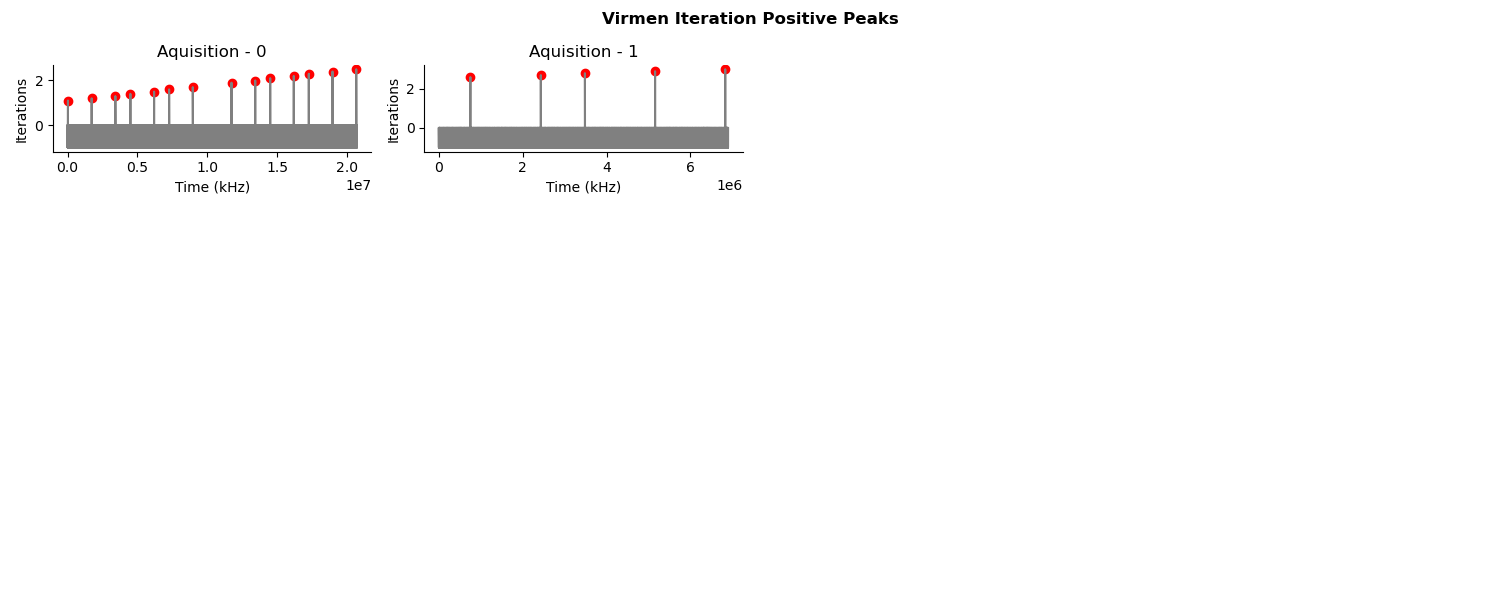

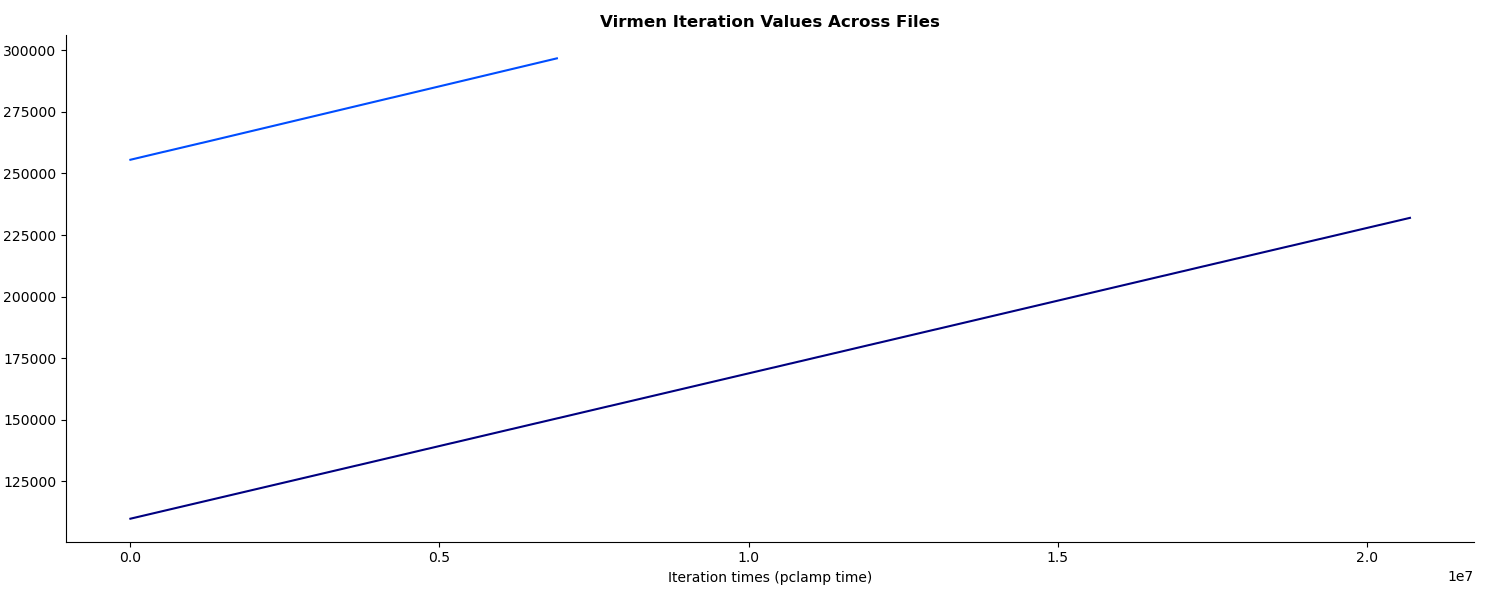

Positive peaks in VIRMEN are separated by 10k iterations. VIRMEN data successfully aligned


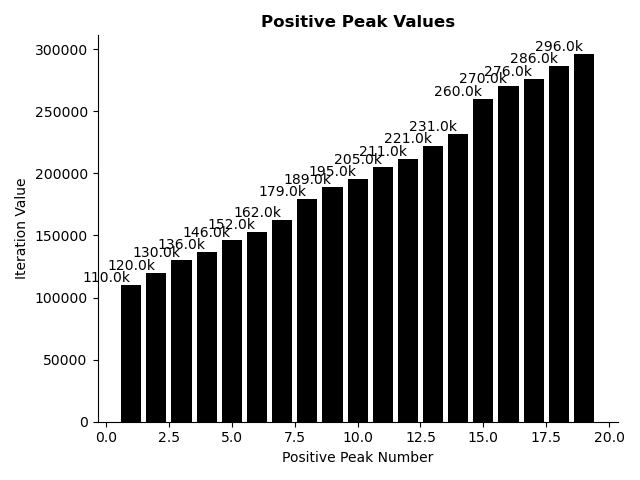

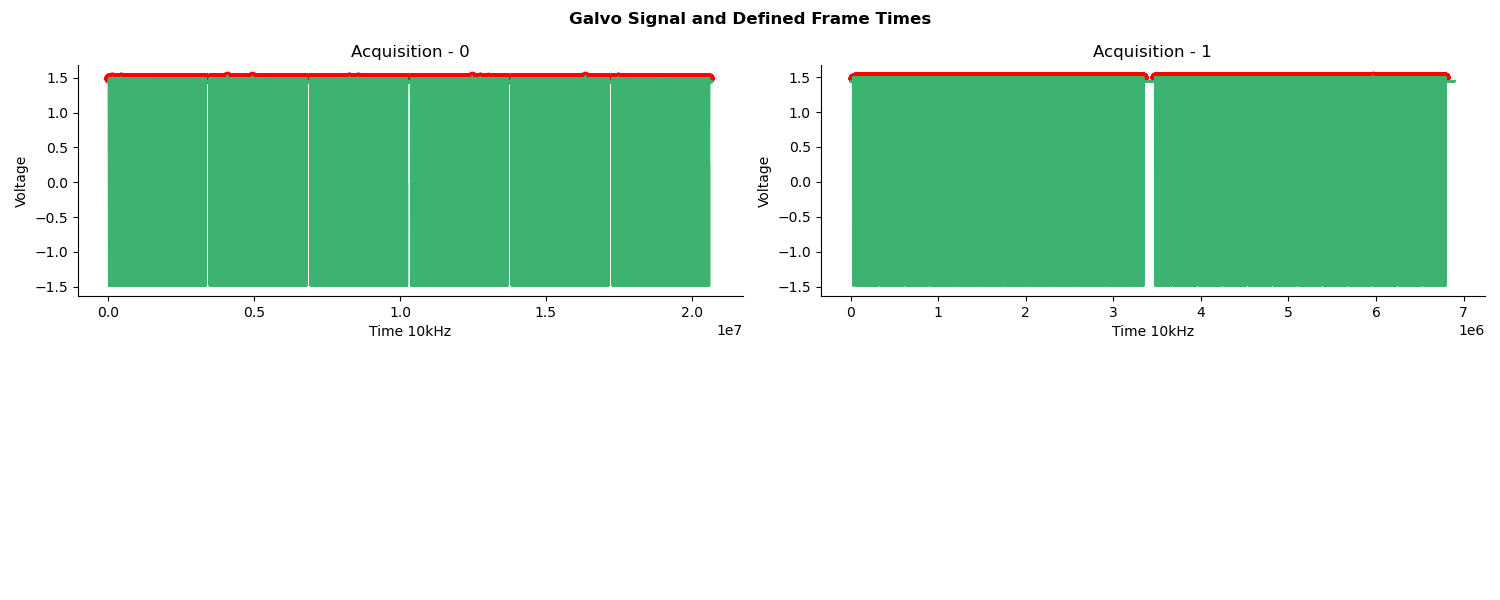

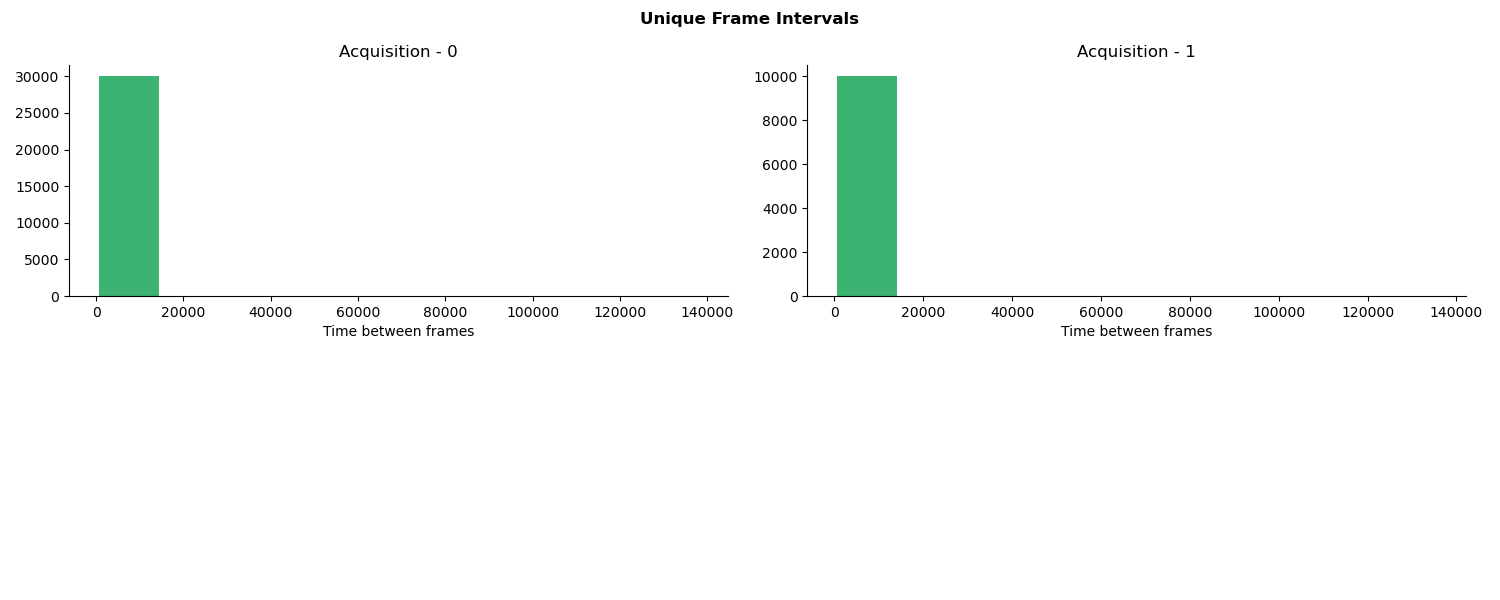

TypeError: align_virmen_data() takes 7 positional arguments but 8 were given

In [6]:
# Load the neural activity
with open(os.path.join(save_directory, 'all_activity_py.pkl'), 'rb') as f:
    activity = pickle.load(f)
dff = activity['dff']
deconvsig = activity['deconv']

# Load the virmen data and align virmen iterations to the pclamp sync files
dataCell, data = align.load_virmen_data(info)
virmen_acq = align.align_virmen_iterations_to_digidata(info['sync_base_path'], info['virmen_channel'])

# Align frame times with pclamp
alignment_info = align.get_frame_times_parallel(info['imaging_base_path'], info['sync_base_path'], info['galvo_channel'], plot_on=1)

# Combine frame time alignment with virmen alignment into a trialized structure
imaging = align.align_virmen_data(dff, deconvsig, virmen_acq, alignment_info, data, dataCell, task)

good = [k for k, v in imaging.items() if v['good_trial'] == 1]
print(f'{len(good)} / {len(imaging)} trials aligned to imaging')

#### **2.2 -** Save imaging trial structure to .pkl

In [ ]:
imaged_trials = save_imaging_data(imaging, info['save_path'])
print('saved', len(imaged_trials), 'imaged trials to', info['save_path'])

## **Section 3 : Trialize virmen behavior**

#### **3.1 -** Load virmen data and create behavior structure

In [ ]:
dataCell, data = align.load_virmen_data(info)
virmen_acq = align.align_virmen_iterations_to_digidata(info['sync_base_path'], info['virmen_channel'])

behavior = align.align_virmen_data_behavior_only(virmen_acq, data, dataCell)

#### **3.2 -** Save behavior trial structure to .pkl

In [ ]:
with open(os.path.join(info['save_path'], 'behavior_data.pkl'), 'wb') as f:
    pickle.dump(behavior, f)